# Variational Quantum Eigensolver for a Single Transmon

This notebook follows the four implementation steps in Section 3 of `vqe.ipynb`. `Coursework_1.ipynb` informs the code style only.

| Step in `vqe.ipynb` | Notebook section |
|---|---|
| 3.1 Step 1 | Build the charge-basis Hamiltonian, map it to Pauli strings, compute the exact reference energy, and build the ansatz. |
| 3.2 Step 2 | Select a target, transpile the circuit, and apply its qubit layout to the observable. |
| 3.3 Step 3 | Define the Estimator cost function, seed the starting angles, and run COBYLA. |
| 3.4 Step 4 | Compare the energies, check padding occupation, and plot convergence. |

**Assumptions and deviations**

- The parameter values were unspecified. The runnable defaults describe a single capacitively shunted Josephson junction with $E_C/h=0.25$ GHz, $E_J/h=12.50$ GHz, $n_g=0$, and $N=5$. This gives $E_J/E_C=50$. The encoded transmon uses four qubits to represent eleven charge states.
- Step 1 retains `efficient_su2` and circular CX entanglement. It uses four repetitions with $R_Y$ rotations because the transmon Hamiltonian is real and the lesson's original gate pattern gave a poor fit in a test with these parameters.
- Steps 2 and 3 use a local target with linear connectivity and a noiseless `StatevectorEstimator`. This preserves transpilation and observable layout while replacing live backend selection, the Runtime session, and finite-shot measurements.
- Step 4 records COBYLA iterations separately from objective evaluations. One iteration can evaluate several trial points, and the last trial can differ from the solution COBYLA returns.

The first code cell loads the tested libraries. The second prints the chosen energy ratio.

In [15]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [16]:
# Circuit parameters
E_C = 3.8740     # Charging energy divided by h [GHz]
E_J = 16.346    # Josephson energy divided by h [GHz]
n_g = 0.0      # Offset charge in units of 2e [dimensionless]
N = 8          # Charge cutoff [integer number of Cooper pairs]

# Reproducibility and optimizer settings
seed = 42
ansatz_reps = 4
max_evals = 8000
optimizer_tol = 1e-7  # Final COBYLA trust-region radius [radians]

assert isinstance(N, int) and N >= 1
assert np.all(np.isfinite([E_C, E_J, n_g])) and E_C > 0 and E_J > 0
print(f"E_J / E_C = {E_J / E_C:g}")

E_J / E_C = 4.21941


### 3.1 Step 1: Map the problem to quantum circuits and operators

The charge basis diagonalizes the electrostatic energy of the island. The integer $n$ counts excess Cooper pairs. Josephson tunnelling transfers one Cooper pair across the junction, so the cosine couples neighbouring charge states. With all energies divided by $h$, the truncated matrix is

$$
H_{nm}
=4(E_C/h)(n-n_g)^2\delta_{nm}
-\frac{E_J}{2h}\bigl(\delta_{n,m+1}+\delta_{n,m-1}\bigr),
\qquad -N\le n,m\le N.
$$

Encode $|n\rangle$ as the computational basis state with integer index $n+N$. For $d=2N+1$ charge states, use $q=\lceil\log_2 d\rceil$ qubits and $D=2^q$ basis states. The embedded matrix is $A=H\oplus E_{\rm pad}I_{D-d}$. Its two blocks have zero coupling. Choose $E_{\rm pad}=\min_n H_{nn}+E_J/h$. A physical basis state has energy $\min_n H_{nn}$, so the variational principle puts the physical ground energy strictly below the padding level.

The code expands $A=\sum_P c_P P$ in tensor products of $I,X,Y,Z$, with $c_P=2^{-q}\operatorname{Tr}(PA)$. Expect four qubits, five padding states, and a successful reconstruction check with 48 Pauli terms. [Qiskit `SparsePauliOp` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.SparsePauliOp)

In [17]:
# The electrostatic cost is diagonal in the number of excess Cooper pairs.
n = np.arange(-N, N + 1)
d = n.size
charging = 4 * E_C * (n - n_g)**2  # Electrostatic cost [GHz]

# Each charge shift in cos(phi) has weight 1/2. The two off-diagonals
# describe tunnelling in both directions, with hops ending at the cutoff.
hopping = np.full(d - 1, -E_J / 2)  # Nearest-neighbour matrix elements [GHz]
H = np.diag(charging) + np.diag(hopping, 1) + np.diag(hopping, -1)

num_qubits = int(d - 1).bit_length()
D = 2**num_qubits

# The cheapest charge state gives an upper bound on the physical ground energy.
# Putting the padding above that bound keeps the ground state in the charge block.
E_pad = charging.min() + E_J  # Padding energy [GHz]
A = E_pad * np.eye(D)
A[:d, :d] = H

# Reconstruct the full matrix to check the physical block and the padding.
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-12, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-10, rtol=0)
print(f"{d} charge states, {num_qubits} qubits, {D - d} padding states")
print(f"Pauli reconstruction passed ({len(hamiltonian)} terms).")

17 charge states, 5 qubits, 15 padding states
Pauli reconstruction passed (78 terms).


#### Exact reference energy

Diagonalize the physical charge block $H$ before building the ansatz, following the order of the example. The lowest eigenvalue is the reference for the chosen cutoff. Expect about $-10.064165$ GHz. The optimizer uses only the Pauli observable and trial circuit.

In [18]:
# Use the physical block so the benchmark contains only charge states.
eigenvalues, _ = np.linalg.eigh(H)
E_exact = float(eigenvalues[0])  # Ground-state energy divided by h [GHz]
print(f"Exact ground-state energy = {E_exact:.12f} GHz")

Exact ground-state energy = -6.391066104933 GHz


#### Ansatz

Prepare $|\psi(\vec{\theta})\rangle=U_{\rm var}(\vec{\theta})|0\rangle^{\otimes q}$. Because $H$ is real symmetric, a ground eigenvector can be chosen real. The $R_Y$ gates vary real amplitudes, and the circular CX layers let the bits encoding charge become correlated. Expect a circuit diagram with 20 angles for the default settings. [Qiskit `efficient_su2` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.efficient_su2)

In [19]:
# RY varies the real amplitudes. Circular CX layers let the qubits
# represent charge distributions with correlations between their bits.
ansatz = efficient_su2(
    hamiltonian.num_qubits,
    su2_gates=["ry"],
    entanglement="circular",
    reps=ansatz_reps,
)
num_params = ansatz.num_parameters  # Each parameter is an angle in radians.
print(f"Logical ansatz: {num_params} parameters, depth {ansatz.depth()}")
print(ansatz.draw(output="text", fold=105))

Logical ansatz: 25 parameters, depth 25
     ┌──────────┐┌───┐     ┌──────────┐                                    ┌───┐     ┌───────────┐»
q_0: ┤ Ry(θ[0]) ├┤ X ├──■──┤ Ry(θ[5]) ├────────────────────────────────────┤ X ├──■──┤ Ry(θ[10]) ├»
     ├──────────┤└─┬─┘┌─┴─┐└──────────┘┌──────────┐                        └─┬─┘┌─┴─┐└───────────┘»
q_1: ┤ Ry(θ[1]) ├──┼──┤ X ├─────■──────┤ Ry(θ[6]) ├──────────────────────────┼──┤ X ├──────■──────»
     ├──────────┤  │  └───┘   ┌─┴─┐    └──────────┘┌──────────┐              │  └───┘    ┌─┴─┐    »
q_2: ┤ Ry(θ[2]) ├──┼──────────┤ X ├─────────■──────┤ Ry(θ[7]) ├──────────────┼───────────┤ X ├────»
     ├──────────┤  │          └───┘       ┌─┴─┐    └──────────┘┌──────────┐  │           └───┘    »
q_3: ┤ Ry(θ[3]) ├──┼──────────────────────┤ X ├─────────■──────┤ Ry(θ[8]) ├──┼────────────────────»
     ├──────────┤  │                      └───┘       ┌─┴─┐    ├──────────┤  │                    »
q_4: ┤ Ry(θ[4]) ├──■──────────────────────────────────┤ X ├─

### 3.2 Step 2: Optimize for target hardware

Use a local `GenericBackendV2` target to specify which gates are available and which qubits can interact. The line topology requires routing some of the circular CX connections. Expect a four-qubit target with `u` and `cx` as its unitary basis gates. [Qiskit `GenericBackendV2` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.providers.fake_provider.GenericBackendV2)

In [20]:
# Define a reproducible local target with nearest-neighbour connectivity.
backend = GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["u", "cx"],
    coupling_map=CouplingMap.from_line(num_qubits),
    seed=seed,
    noise_info=False,
)
target = backend.target
print(f"Local target: {target.num_qubits} qubits, operations {backend.operation_names}")

Local target: 5 qubits, operations ['u', 'cx', 'reset', 'delay', 'measure']


#### Transpile the ansatz

Translate the logical circuit into the target's instruction set and route its two-qubit gates. The parameter set should survive transpilation. Expect the transpiled depth, gate counts, and circuit diagram.

In [21]:
# Compile the circuit once so every objective evaluation uses the same layout.
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
ansatz_isa = pm.run(ansatz)
assert set(ansatz_isa.parameters) == set(ansatz.parameters)

print(f"Transpiled depth: {ansatz_isa.depth()}")
print(f"Transpiled gate counts: {dict(ansatz_isa.count_ops())}")
print(ansatz_isa.draw(output="text", fold=105, idle_wires=False))

Transpiled depth: 66
Transpiled gate counts: {'cx': 68, 'u': 37}
global phase: 5.6338
         ┌─────────────┐                              ┌───┐                    ┌───┐»
q_4 -> 0 ┤ U(θ[4],0,0) ├──■───────────────────────────┤ X ├────────────■───────┤ X ├»
         ├─────────────┤┌─┴─┐     ┌─────────────┐     └─┬─┘          ┌─┴─┐     └─┬─┘»
q_0 -> 1 ┤ U(θ[0],0,0) ├┤ X ├──■──┤ U(θ[5],0,0) ├───────■────────────┤ X ├───────■──»
         ├─────────────┤└───┘┌─┴─┐└─────────────┘┌─────────────┐     └───┘          »
q_1 -> 2 ┤ U(θ[1],0,0) ├─────┤ X ├───────■───────┤ U(θ[6],0,0) ├────────────────────»
         ├─────────────┤     └───┘     ┌─┴─┐     └─────────────┘┌─────────────┐     »
q_2 -> 3 ┤ U(θ[2],0,0) ├───────────────┤ X ├────────────■───────┤ U(θ[7],0,0) ├──■──»
         ├─────────────┤               └───┘          ┌─┴─┐     └─────────────┘┌─┴─┐»
q_3 -> 4 ┤ U(θ[3],0,0) ├──────────────────────────────┤ X ├────────────────────┤ X ├»
         └─────────────┘                              

#### Apply the layout to the Hamiltonian

A logical qubit can finish on a different wire after routing. Apply the circuit layout to the Pauli strings so each term still acts on the intended charge bits. Expect the list mapping logical qubits to final wires. [Qiskit `SparsePauliOp.apply_layout` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.SparsePauliOp#apply_layout)

In [22]:
# Use the circuit's full layout, including any permutation from routing.
hamiltonian_isa = hamiltonian.apply_layout(ansatz_isa.layout)
assert hamiltonian_isa.num_qubits == ansatz_isa.num_qubits
print(f"Logical-to-final qubits: {ansatz_isa.layout.final_index_layout()}")

Logical-to-final qubits: [4, 3, 2, 1, 0]


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values

For this local implementation, `StatevectorEstimator` computes the expectation value of the layout-adjusted Pauli operator with no sampling noise. COBYLA minimizes the equivalent logical energy

$$
E_{\rm var}(\vec{\theta})
=\langle\psi(\vec{\theta})|A|\psi(\vec{\theta})\rangle
\ge E_{\rm exact},
$$

up to floating-point precision. The inequality follows because the lowest eigenvalue of $A$ belongs to the physical block. The cost function records every trial energy, while the callback records the energy that COBYLA reports at each iteration. The next cell defines these functions and initializes the histories. It produces no printed output. [Qiskit `StatevectorEstimator` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [23]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return the trial energy [GHz] and record this objective evaluation."""

    # The Estimator binds params in the circuit's parameter order.
    pub = (ansatz, hamiltonian, params)
    energy = float(estimator.run([pub]).result()[0].data.evs.item())

    # Store a copy because an optimizer can reuse the input array.
    cost_history_dict["prev_vector"] = np.copy(params)
    cost_history_dict["cost_history"].append(energy)
    return energy


def record_iteration(intermediate_result):
    """Record the reported iteration energy [GHz] without another evaluation."""
    cost_history_dict["iters"].append(intermediate_result.nit)
    cost_history_dict["iteration_energy"].append(float(intermediate_result.fun))


cost_history_dict = {
    "prev_vector": None,
    "cost_history": [],
    "iters": [],
    "iteration_energy": [],
}

#### Initial parameters

Draw $\vec{\theta}_0$ uniformly from $[0,2\pi)$ as in the procedure, using a fixed seed for reproducibility. Expect a confirmation that 20 angles were initialized.

In [24]:
# The fixed seed reproduces the same starting point for this ansatz.
rng = np.random.default_rng(seed)
x0 = 2 * np.pi * rng.random(num_params)  # Initial angles [radians]
print(f"Initialised {x0.size} angles.")

Initialised 25 angles.


#### Run the classical optimizer

COBYLA varies the angles using only energy evaluations. SciPy drives the iteration loop and calls `record_iteration` with its current result. In the pinned SciPy version, the `maxiter` option caps objective evaluations. The execution cell stores the result in `res`, and the next cell prints the termination message, final energy, and evaluation count. [SciPy COBYLA documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/optimize.minimize-cobyla.html)

In [25]:
# Clear the histories so rerunning this cell starts a fresh optimization.
cost_history_dict["prev_vector"] = None
for key in ("cost_history", "iters", "iteration_energy"):
    cost_history_dict[key].clear()

# Zero precision requests a noiseless statevector expectation value.
estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa, hamiltonian_isa, estimator),
    method="COBYLA",
    callback=record_iteration,
    options={"maxiter": max_evals, "tol": optimizer_tol},
)

In [26]:
print(res)

 message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
 success: False
  status: 3
     fun: -6.3783418744995295
       x: [ 6.194e+00  4.688e+00 ...  6.044e+00  4.711e+00]
    nfev: 8000
   maxcv: 0.0


### 3.4 Step 4: Post-process results

Use the energy at the solution returned by COBYLA and compute $\lvert E_{\rm VQE}-E_{\rm exact}\rvert$. Check the evaluation count, then bind the solution to the logical circuit to measure its padding probability and independently verify the layout-adjusted energy.

As a physics sanity check, expanding the cosine to quartic order gives the ground-state estimate

$$
E_0/h \approx -E_J/h + \sqrt{2(E_J/h)(E_C/h)} - \frac{E_C}{4h}.
$$

Expect the VQE and exact energies to agree closely, with negligible padding occupation. The quartic estimate is a separate approximation. [Koch et al., *Charge-insensitive qubit design derived from the Cooper pair box*](https://arxiv.org/abs/cond-mat/0703002)

In [27]:
# The last trial can differ from the point COBYLA returns.
assert len(cost_history_dict["cost_history"]) == res.nfev
last_trial_is_solution = np.array_equal(cost_history_dict["prev_vector"], res.x)

E_vqe = float(res.fun)  # Returned variational energy divided by h [GHz]
absolute_error = abs(E_vqe - E_exact)  # [GHz]

# Bind by parameter identity, then inspect amplitudes in logical charge order.
params_opt = dict(zip(ansatz_isa.parameters, res.x))
psi_opt = Statevector.from_instruction(ansatz.assign_parameters(params_opt))
p_pad = float(np.sum(np.abs(psi_opt.data[d:])**2))  # Probability [dimensionless]

# Check that layout and parameter binding preserve the energy.
E_logical = float(np.vdot(psi_opt.data, A @ psi_opt.data).real)  # [GHz]
assert np.isclose(E_logical, E_vqe, atol=1e-9, rtol=0)
assert E_vqe >= E_exact - 1e-9

# Compare with the harmonic zero-point energy and first quartic correction.
E_approx = -E_J + np.sqrt(2 * E_J * E_C) - E_C / 4  # [GHz]
print(f"Last trial equals returned solution: {last_trial_is_solution}")
print(f"Exact energy:           {E_exact:.12f} GHz")
print(f"VQE energy:             {E_vqe:.12f} GHz")
print(f"Absolute error:         {absolute_error:.3e} GHz")
print(f"Padding probability:    {p_pad:.3e}")
print(f"Transmon approximation: {E_approx:.12f} GHz")

Last trial equals returned solution: True
Exact energy:           -6.391066104933 GHz
VQE energy:             -6.378341874500 GHz
Absolute error:         1.272e-02 GHz
Padding probability:    1.127e-04
Transmon approximation: -6.060664742631 GHz


#### Convergence plot

Plot the energy reported by the callback against the COBYLA iteration number. Expect the curve to fall towards the dashed horizontal line at the exact ground energy. The callback trace and the final `res.fun` can end at slightly different energies.

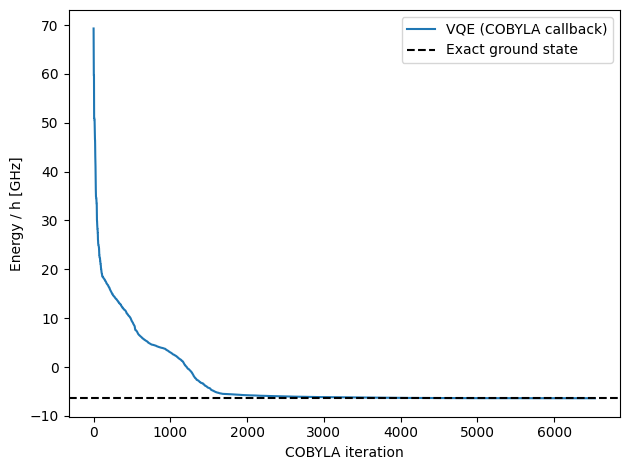

In [28]:
# Plot optimizer iterations separately from individual trial evaluations.
fig, ax = plt.subplots()
ax.plot(
    cost_history_dict["iters"],
    cost_history_dict["iteration_energy"],
    label="VQE (COBYLA callback)",
)
ax.axhline(E_exact, color="black", linestyle="--", label="Exact ground state")
ax.set_xlabel("COBYLA iteration")
ax.set_ylabel("Energy / h [GHz]")
ax.legend()
fig.tight_layout()
plt.show()

## Results and limitations

With the defaults and tested library versions, COBYLA converged after 5,688 objective evaluations.

| Quantity | Tested value |
|---|---:|
| Exact ground-state energy divided by $h$ | $-10.064164871841$ GHz |
| VQE ground-state energy divided by $h$ | $-10.064164871838$ GHz |
| Absolute VQE error | $2.66\times10^{-12}$ GHz |
| Padding probability | $6.69\times10^{-15}$ |
| Quartic transmon estimate divided by $h$ | $-10.062500000000$ GHz |

The VQE error measures agreement at the chosen charge cutoff. In a separate exact diagonalization, increasing the cutoff from $N=5$ to $N=7$ lowered the reference energy by about $3.00\times10^{-5}$ GHz. The reported VQE precision applies to a noiseless simulation with this ansatz and seed. Larger cutoffs increase the cost of the dense Pauli decomposition and statevector simulation, and changing the parameters can change how well COBYLA converges.